# Data Science Final Hackathon — AI Powered E-Commerce Customer Intelligence System

**Goal:** Complete the hackathon yourself, step by step, using the supplied `ecommerce_hackathon.db`.

This notebook follows the student brief:

1. Database inspection and cleaning
2. SQL business analysis
3. Exploratory data analysis
4. Customer churn ML
5. Feed-forward neural network
6. Review sentiment NLP
7. Save models/results for the Streamlit application

> **Important:** Run each cell in order. Read the markdown explanation before executing the code, and write your own short explanation of important cleaning/modeling decisions in the marked sections.


## Hackathon rules to keep in mind

- Use **SQLite3** to connect to the supplied database.
- Do not convert the complete database to CSV before starting.
- Use SQL for the required business queries.
- Inspect and clean the raw data before modeling.
- Do not delete problematic records without a reason.
- Avoid data leakage in the churn model.
- Use saved models in the Streamlit application rather than hard-coded predictions.

The required churn feature period is **up to 31 May 2026** and the churn target window is **1 June 2026 through 31 August 2026**.


In [1]:
# Cell 1 — Imports and configuration

from pathlib import Path
import sqlite3
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

# Put ecommerce_hackathon.db in the same folder as this notebook.
DB_PATH = Path("ecommerce_hackathon.db")

# Output folders for your own work
Path("outputs").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("sql").mkdir(exist_ok=True)

print("Database path:", DB_PATH.resolve())
print("Database exists:", DB_PATH.exists())


Database path: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\ecommerce_hackathon.db
Database exists: True


## 1. Connect to SQLite

First prove that the database is accessible. Do not start modeling yet.

**Your task:** If `Database exists` is `False`, place `ecommerce_hackathon.db` beside this notebook and rerun the cell.


In [2]:
# Cell 2 — SQLite connection

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"{DB_PATH} was not found. Put ecommerce_hackathon.db in the same folder as this notebook."
    )

conn = sqlite3.connect(DB_PATH)
print("SQLite connection successful.")


SQLite connection successful.


In [3]:
# Cell 3 — Inspect tables

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
    conn
)
tables


,name
0,customers
1,orders
2,products
3,reviews


In [4]:
# Cell 4 — Show row counts for all tables

row_counts = []
for table in tables["name"]:
    count = pd.read_sql_query(f"SELECT COUNT(*) AS rows FROM {table};", conn).iloc[0, 0]
    row_counts.append({"table": table, "rows": int(count)})

row_counts_df = pd.DataFrame(row_counts)
row_counts_df["rows"].sum(), row_counts_df


(np.int64(100000),
        table   rows
 0  customers   8000
 1     orders  65000
 2   products   1000
 3    reviews  26000)

In [5]:
# Cell 5 — Load each table from SQLite for inspection
# This is NOT a manual database-to-CSV conversion. We are extracting tables into DataFrames
# for analysis after connecting to SQLite.

customers = pd.read_sql_query("SELECT * FROM customers;", conn)
products = pd.read_sql_query("SELECT * FROM products;", conn)
orders = pd.read_sql_query("SELECT * FROM orders;", conn)
reviews = pd.read_sql_query("SELECT * FROM reviews;", conn)

for name, df in {
    "customers": customers,
    "products": products,
    "orders": orders,
    "reviews": reviews
}.items():
    print(f"{name}: shape={df.shape}")
    print(df.columns.tolist())
    display(df.head(3))
    print("-" * 80)


customers: shape=(8000, 9)
['customer_id', 'customer_name', 'age', 'gender', 'city', 'signup_date', 'membership_type', 'email', 'phone']


,customer_id,customer_name,age,gender,city,signup_date,membership_type,email,phone
0,1,Hassan Khan,20.0,Male,Karachi,2026-02-27,Standard,hassan.khan1@example.com,+92-3241-4744854
1,2,Maham Raza,33.0,Female,Rawalpindi,2025-10-17,Silver,maham.raza2@example.com,+92-3421-8078673
2,3,Ahmed Khan,25.0,Male,Karachi,2022-07-11,Standard,ahmed.khan3@example.com,+92-3139-9478454


--------------------------------------------------------------------------------
products: shape=(1000, 6)
['product_id', 'product_name', 'category', 'brand', 'unit_price', 'stock_quantity']


,product_id,product_name,category,brand,unit_price,stock_quantity
0,1,Readings Exam Guide Premium,Books & Stationery,Readings,566.45,103
1,2,Samsung Webcam Classic,Electronics,Samsung,10567.23,138
2,3,CA Sports Water Bottle Classic,Sports & Fitness,CA Sports,6665.04,63


--------------------------------------------------------------------------------
orders: shape=(65000, 10)
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'returned']


,order_id,customer_id,product_id,order_date,quantity,unit_price,discount,payment_method,delivery_days,returned
0,1,2367,389,2026-04-30,1,398.27,0.108,Cash on Delivery,1.0,0
1,2,2038,927,2026-02-09,2,44488.20,0.084,Debit/Credit Card,1.0,0
2,3,6285,909,2026-03-30,1,4719.91,0.125,Cash on Delivery,1.0,0


--------------------------------------------------------------------------------
reviews: shape=(26000, 6)
['review_id', 'customer_id', 'product_id', 'review_date', 'rating', 'review_text']


,review_id,customer_id,product_id,review_date,rating,review_text
0,1,7210,787,2026-07-28,4,"I would buy this again, item feels durable. Re..."
1,2,5566,765,2026-05-16,5,"Very satisfied, seller description was accurat..."
2,3,6106,743,2025-10-21,4,"Very satisfied, quality feels premium. Good va..."


--------------------------------------------------------------------------------


# Task A — Data Quality Inspection and Cleaning

The brief asks you to identify:

- missing values
- duplicates
- invalid numerical values
- inconsistent text categories
- invalid dates
- suspicious records

Do not delete records blindly. For every important cleaning decision, be able to answer:

> **What was wrong, what did I do, and why was that decision reasonable?**


In [6]:
# Cell 6 — Missing values

for name, df in {
    "customers": customers,
    "products": products,
    "orders": orders,
    "reviews": reviews
}.items():
    print(f"\n{name}")
    missing = df.isna().sum().sort_values(ascending=False)
    display(missing[missing > 0].to_frame("missing_values"))



customers


,missing_values
age,100



products


,missing_values
brand,20



orders


,missing_values
payment_method,55
delivery_days,40



reviews


,missing_values
review_text,48


In [7]:
# Cell 7 — Duplicate primary keys

primary_keys = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "reviews": "review_id"
}

for name, key in primary_keys.items():
    df = {"customers": customers, "products": products, "orders": orders, "reviews": reviews}[name]
    duplicates = df[key].duplicated().sum()
    print(f"{name}: duplicate {key} values = {duplicates}")


customers: duplicate customer_id values = 0
products: duplicate product_id values = 0
orders: duplicate order_id values = 0
reviews: duplicate review_id values = 0


In [8]:
# Cell 8 — Invalid numerical values

print("Customers: invalid ages")
display(customers.loc[~customers["age"].between(18, 100, inclusive="both"), ["customer_id", "age"]].head(20))

print("Products: non-positive prices")
display(products.loc[products["unit_price"] <= 0, ["product_id", "unit_price"]].head(20))

print("Orders: non-positive quantity")
display(orders.loc[orders["quantity"] <= 0, ["order_id", "quantity"]].head(20))

print("Orders: non-positive unit price")
display(orders.loc[orders["unit_price"] <= 0, ["order_id", "unit_price"]].head(20))

print("Orders: invalid discount")
display(orders.loc[~orders["discount"].between(0, 1, inclusive="both"), ["order_id", "discount"]].head(20))

print("Reviews: ratings outside 1-5")
display(reviews.loc[~reviews["rating"].between(1, 5, inclusive="both"), ["review_id", "rating"]].head(20))


Customers: invalid ages


,customer_id,age
45,46,NaN
49,50,NaN
221,222,NaN
224,225,NaN
237,238,NaN
269,270,NaN
612,613,NaN
644,645,NaN
656,657,NaN
671,672,NaN


Products: non-positive prices


,product_id,unit_price


Orders: non-positive quantity


...

,order_id,unit_price
1342,1343,-126669.18
2110,2111,-5001.21
2438,2439,-1576.66
2726,2727,-4776.16
2781,2782,-1503.95
5615,5616,-1003.46
9713,9714,-556.96
10217,10218,-3292.94
10282,10283,-4067.62
14125,14126,-8136.83


Orders: invalid discount


,order_id,discount


Reviews: ratings outside 1-5


,review_id,rating
1284,1285,6
1454,1455,0
2783,2784,6
4119,4120,0
4870,4871,0
5708,5709,0
6466,6467,0
7117,7118,6
7417,7418,0
9042,9043,0


In [9]:
# Cell 9 — Date parsing and invalid-date counts

date_columns = {
    "customers": ("signup_date", customers),
    "orders": ("order_date", orders),
    "reviews": ("review_date", reviews)
}

for name, (col, df) in date_columns.items():
    parsed = pd.to_datetime(df[col], errors="coerce")
    print(f"{name}.{col}: invalid/unparseable dates =", int(parsed.isna().sum()))


customers.signup_date: invalid/unparseable dates = 0
orders.order_date: invalid/unparseable dates = 30
reviews.review_date: invalid/unparseable dates = 16


In [10]:
# Cell 10 — Inconsistent text categories

text_columns = {
    "customers": ["gender", "city", "membership_type"],
    "products": ["category", "brand"],
    "orders": ["payment_method"]
}

for name, cols in text_columns.items():
    df = {"customers": customers, "products": products, "orders": orders}[name]
    print(f"\n{name}")
    for col in cols:
        print(f"--- {col} ---")
        print(df[col].dropna().astype(str).value_counts().head(20).to_string())



customers
--- gender ---
gender
Male      4517
Female    3483
--- city ---
city
Karachi       2149
Lahore        1461
Islamabad      798
Rawalpindi     658
Faisalabad     564
Multan         480
Peshawar       399
Hyderabad      318
Gujranwala     316
Quetta         237
Sialkot        234
Bahawalpur     159
Sargodha       157
KARACHI         10
karachi          7
 Lahore          6
lahore           5
LAHORE           4
 Karachi         3
MULTAN           3
--- membership_type ---
membership_type
Standard    4629
Silver      1776
Gold        1113
Premium      482

products
--- category ---
category
Fashion               218
Electronics           179
Home & Kitchen        132
Beauty                130
Groceries             100
Sports & Fitness       87
Books & Stationery     74
Baby & Kids            62
Fashion                 3
electronics             3
ELECTRONICS             2
BEAUTY                  2
FASHION                 2
beauty                  1
Baby & Kids             1
Elect

### Your written data-quality summary

After inspecting the cells above, write 4–8 bullets here in your own words.

Example structure:

- `orders.order_date`: explain how invalid dates will be handled.
- `orders.quantity`: explain why non-positive quantities are excluded from revenue/modeling.
- `reviews.rating`: explain how invalid ratings are handled.
- Text categories: explain why whitespace/case normalization is appropriate.
- Missing values: explain whether you impute or exclude each important field.

**Do not copy a generic answer. Use the issues you actually find in your database.**


# Cleaning

We will keep the original raw DataFrames unchanged and create cleaned copies.

For business revenue analysis, an order must have:

- a valid order date
- positive quantity
- positive unit price
- a valid discount between 0 and 1

For reviews, unusable review records will be removed only for the NLP task.

For customer/product attributes, we will normalize text and use model pipelines to handle missing values rather than deleting customers unnecessarily.


In [11]:
# Cell 11 — Clean customer data

customers_clean = customers.copy()

# Normalize selected text fields
for col in ["gender", "city", "membership_type"]:
    customers_clean[col] = (
        customers_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

customers_clean["gender"] = customers_clean["gender"].str.title()
customers_clean["city"] = customers_clean["city"].str.title()
customers_clean["membership_type"] = customers_clean["membership_type"].str.title()

# Parse dates
customers_clean["signup_date"] = pd.to_datetime(
    customers_clean["signup_date"], errors="coerce"
)

print(customers_clean.shape)
display(customers_clean.head())


(8000, 9)


,customer_id,customer_name,age,gender,city,signup_date,membership_type,email,phone
0,1,Hassan Khan,20.0,Male,Karachi,2026-02-27,Standard,hassan.khan1@example.com,+92-3241-4744854
1,2,Maham Raza,33.0,Female,Rawalpindi,2025-10-17,Silver,maham.raza2@example.com,+92-3421-8078673
2,3,Ahmed Khan,25.0,Male,Karachi,2022-07-11,Standard,ahmed.khan3@example.com,+92-3139-9478454
3,4,Salman Khan,26.0,Male,Lahore,2025-02-23,Standard,salman.khan4@example.com,+92-3193-8038374
4,5,Noor Awan,27.0,Female,Lahore,2025-04-21,Standard,noor.awan5@example.com,+92-3210-3678638


In [12]:
# Cell 12 — Clean product data

products_clean = products.copy()

for col in ["product_name", "category", "brand"]:
    products_clean[col] = (
        products_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

products_clean["category"] = products_clean["category"].str.title()
products_clean["brand"] = products_clean["brand"].str.title()

products_clean["unit_price"] = pd.to_numeric(products_clean["unit_price"], errors="coerce")
products_clean["stock_quantity"] = pd.to_numeric(products_clean["stock_quantity"], errors="coerce")

print(products_clean.shape)
display(products_clean.head())


(1000, 6)


,product_id,product_name,category,brand,unit_price,stock_quantity
0,1,Readings Exam Guide Premium,Books & Stationery,Readings,566.45,103
1,2,Samsung Webcam Classic,Electronics,Samsung,10567.23,138
2,3,CA Sports Water Bottle Classic,Sports & Fitness,Ca Sports,6665.04,63
3,4,LU Spice Mix Classic,Groceries,Lu,516.49,113
4,5,L'Oreal Shampoo 2026,Beauty,L'Oreal,2581.35,107


In [13]:
# Cell 13 — Clean orders

orders_clean = orders.copy()

orders_clean["order_date"] = pd.to_datetime(orders_clean["order_date"], errors="coerce")
orders_clean["quantity"] = pd.to_numeric(orders_clean["quantity"], errors="coerce")
orders_clean["unit_price"] = pd.to_numeric(orders_clean["unit_price"], errors="coerce")
orders_clean["discount"] = pd.to_numeric(orders_clean["discount"], errors="coerce")
orders_clean["delivery_days"] = pd.to_numeric(orders_clean["delivery_days"], errors="coerce")

orders_clean["payment_method"] = (
    orders_clean["payment_method"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# Valid transaction flag
orders_clean["valid_transaction"] = (
    orders_clean["order_date"].notna()
    & orders_clean["quantity"].gt(0)
    & orders_clean["unit_price"].gt(0)
    & orders_clean["discount"].between(0, 1, inclusive="both")
)

orders_valid = orders_clean.loc[orders_clean["valid_transaction"]].copy()

# Business definition of net revenue:
# discounted order value, with returned orders contributing zero net revenue.
orders_valid["gross_revenue"] = (
    orders_valid["quantity"] * orders_valid["unit_price"]
)
orders_valid["discount_amount"] = (
    orders_valid["gross_revenue"] * orders_valid["discount"]
)
orders_valid["net_before_return"] = (
    orders_valid["gross_revenue"] - orders_valid["discount_amount"]
)
orders_valid["net_revenue"] = np.where(
    orders_valid["returned"].astype(str).str.strip().str.lower().isin(["yes", "true", "1"]),
    0,
    orders_valid["net_before_return"]
)

print("Raw orders:", len(orders_clean))
print("Valid transactions:", len(orders_valid))
display(orders_valid.head())


Raw orders: 65000
Valid transactions: 64890


,order_id,customer_id,product_id,order_date,quantity,unit_price,discount,payment_method,delivery_days,returned,valid_transaction,gross_revenue,discount_amount,net_before_return,net_revenue
0,1,2367,389,2026-04-30,1,398.27,0.108,Cash On Delivery,1.0,0,True,398.27,43.01316,355.25684,355.25684
1,2,2038,927,2026-02-09,2,44488.20,0.084,Debit/Credit Card,1.0,0,True,88976.40,7474.01760,81502.38240,81502.38240
2,3,6285,909,2026-03-30,1,4719.91,0.125,Cash On Delivery,1.0,0,True,4719.91,589.98875,4129.92125,4129.92125
3,4,3714,117,2026-03-24,1,2053.64,0.118,Easypaisa,4.0,0,True,2053.64,242.32952,1811.31048,1811.31048
4,5,3021,733,2024-12-13,1,31378.77,0.087,Debit/Credit Card,2.0,0,True,31378.77,2729.95299,28648.81701,28648.81701


In [14]:
# Cell 14 — Clean reviews

reviews_clean = reviews.copy()

reviews_clean["review_date"] = pd.to_datetime(
    reviews_clean["review_date"], errors="coerce"
)
reviews_clean["rating"] = pd.to_numeric(reviews_clean["rating"], errors="coerce")
reviews_clean["review_text"] = (
    reviews_clean["review_text"]
    .astype("string")
    .str.strip()
)

reviews_nlp = reviews_clean.loc[
    reviews_clean["review_date"].notna()
    & reviews_clean["rating"].between(1, 5, inclusive="both")
    & reviews_clean["review_text"].notna()
    & reviews_clean["review_text"].str.len().gt(0)
].copy()

def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    return "Positive"

reviews_nlp["sentiment"] = reviews_nlp["rating"].apply(rating_to_sentiment)

print("Raw reviews:", len(reviews_clean))
print("Usable NLP reviews:", len(reviews_nlp))
display(reviews_nlp[["rating", "sentiment", "review_text"]].head())
display(reviews_nlp["sentiment"].value_counts())


Raw reviews: 26000
Usable NLP reviews: 25869


,rating,sentiment,review_text
0,4,Positive,"I would buy this again, item feels durable. Re..."
1,5,Positive,"Very satisfied, seller description was accurat..."
2,4,Positive,"Very satisfied, quality feels premium. Good va..."
3,4,Positive,"Product arrived in great condition, quality fe..."
4,4,Positive,"Good experience overall, packing was neat. Wil..."


sentiment
Positive    18410
Neutral      5454
Negative     2005
Name: count, dtype: int64

# Task B — SQL Business Analysis

The five required queries are executed against SQLite.

**Important:** The SQL below is deliberately visible so you can explain it during your presentation. We are not replacing SQL with Pandas for these required business questions.


In [15]:
# Cell 15 — SQL Query 1: Total net revenue

query_1 = '''
SELECT
    SUM(
        CASE
            WHEN LOWER(TRIM(CAST(o.returned AS TEXT))) IN ('yes', 'true', '1')
                THEN 0
            ELSE o.quantity * o.unit_price * (1 - o.discount)
        END
    ) AS total_net_revenue
FROM orders o
WHERE o.order_date IS NOT NULL
  AND o.quantity > 0
  AND o.unit_price > 0
  AND o.discount BETWEEN 0 AND 1;
'''

sql_total_revenue = pd.read_sql_query(query_1, conn)
sql_total_revenue


,total_net_revenue
0,8.654913e+08


In [16]:
# Cell 16 — SQL Query 2: Top 10 customers by spending

query_2 = '''
SELECT
    c.customer_name,
    c.city,
    COUNT(DISTINCT o.order_id) AS number_of_orders,
    SUM(
        CASE
            WHEN LOWER(TRIM(CAST(o.returned AS TEXT))) IN ('yes', 'true', '1')
                THEN 0
            ELSE o.quantity * o.unit_price * (1 - o.discount)
        END
    ) AS total_spending
FROM customers c
JOIN orders o
    ON c.customer_id = o.customer_id
WHERE o.order_date IS NOT NULL
  AND o.quantity > 0
  AND o.unit_price > 0
  AND o.discount BETWEEN 0 AND 1
GROUP BY c.customer_id, c.customer_name, c.city
ORDER BY total_spending DESC
LIMIT 10;
'''

sql_top_customers = pd.read_sql_query(query_2, conn)
sql_top_customers


,customer_name,city,number_of_orders,total_spending
0,Shahzaib Abbasi,Lahore,43,1.537801e+06
1,Zoya Awan,Lahore,55,1.515401e+06
2,Ahmed Qureshi,Lahore,27,1.452407e+06
3,Kiran Farooq,Karachi,61,1.353157e+06
4,Laiba Khan,Karachi,41,1.340945e+06
5,Adeel Khan,Karachi,42,1.333847e+06
6,Fahad Khan,Islamabad,53,1.252694e+06
7,Bilal Awan,Karachi,49,1.248564e+06
8,Imran Qureshi,Karachi,46,1.247070e+06
9,Danish Awan,Faisalabad,44,1.240877e+06


In [17]:
# Cell 17 — SQL Query 3: Category-wise revenue, order count and quantity sold

query_3 = '''
SELECT
    p.category,
    SUM(
        CASE
            WHEN LOWER(TRIM(CAST(o.returned AS TEXT))) IN ('yes', 'true', '1')
                THEN 0
            ELSE o.quantity * o.unit_price * (1 - o.discount)
        END
    ) AS revenue,
    COUNT(DISTINCT o.order_id) AS order_count,
    SUM(o.quantity) AS quantity_sold
FROM orders o
JOIN products p
    ON o.product_id = p.product_id
WHERE o.order_date IS NOT NULL
  AND o.quantity > 0
  AND o.unit_price > 0
  AND o.discount BETWEEN 0 AND 1
GROUP BY p.category
ORDER BY revenue DESC;
'''

sql_category = pd.read_sql_query(query_3, conn)
sql_category


,category,revenue,order_count,quantity_sold
0,Electronics,5.897190e+08,11043,15476
1,Home & Kitchen,6.529115e+07,7532,10636
2,Fashion,5.464882e+07,12034,16856
3,Sports & Fitness,5.147900e+07,7066,9928
4,Beauty,4.351566e+07,11544,16039
5,Baby & Kids,2.701127e+07,3703,5264
6,electronics,1.134563e+07,182,253
7,Groceries,7.829888e+06,6054,8467
8,Books & Stationery,7.312427e+06,4924,6819
9,ELECTRONICS,3.038298e+06,276,380


In [18]:
# Cell 18 — SQL Query 4: Monthly net revenue trend

query_4 = '''
SELECT
    strftime('%Y-%m', o.order_date) AS month,
    SUM(
        CASE
            WHEN LOWER(TRIM(CAST(o.returned AS TEXT))) IN ('yes', 'true', '1')
                THEN 0
            ELSE o.quantity * o.unit_price * (1 - o.discount)
        END
    ) AS net_revenue
FROM orders o
WHERE o.order_date IS NOT NULL
  AND o.quantity > 0
  AND o.unit_price > 0
  AND o.discount BETWEEN 0 AND 1
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY month;
'''

sql_monthly = pd.read_sql_query(query_4, conn)
sql_monthly


,month,net_revenue
0,NaN,3.213347e+05
1,2022-03,8.425491e+03
2,2022-04,8.074637e+04
3,2022-05,1.194615e+05
4,2022-06,2.039121e+05
5,2022-07,8.977847e+04
6,2022-08,6.989960e+05
7,2022-09,2.933531e+05
8,2022-10,3.617493e+05
9,2022-11,8.957299e+05


In [19]:
# Cell 19 — SQL Query 5: Top 5 products by net revenue

query_5 = '''
SELECT
    p.product_name,
    p.category,
    SUM(
        CASE
            WHEN LOWER(TRIM(CAST(o.returned AS TEXT))) IN ('yes', 'true', '1')
                THEN 0
            ELSE o.quantity * o.unit_price * (1 - o.discount)
        END
    ) AS net_revenue
FROM orders o
JOIN products p
    ON o.product_id = p.product_id
WHERE o.order_date IS NOT NULL
  AND o.quantity > 0
  AND o.unit_price > 0
  AND o.discount BETWEEN 0 AND 1
GROUP BY p.product_id, p.product_name, p.category
ORDER BY net_revenue DESC
LIMIT 5;
'''

sql_top_products = pd.read_sql_query(query_5, conn)
sql_top_products


,product_name,category,net_revenue
0,Samsung Headphones Classic,Electronics,1.056982e+08
1,Anker Headphones Classic,Electronics,6.601398e+07
2,Dawlance LED TV Premium,Electronics,1.903070e+07
3,Infinix LED TV 2026,Electronics,1.565400e+07
4,Dawlance Router Eco,Electronics,1.417660e+07


In [20]:
# Cell 20 — Save the five required SQL queries

sql_text = f'''
-- 1. Total net revenue
{query_1}

-- 2. Top 10 customers
{query_2}

-- 3. Category-wise revenue
{query_3}

-- 4. Monthly net revenue
{query_4}

-- 5. Top 5 products
{query_5}
'''

Path("sql/business_queries.sql").write_text(sql_text, encoding="utf-8")
print("Saved:", Path("sql/business_queries.sql").resolve())


Saved: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\sql\business_queries.sql


# Task C — Exploratory Data Analysis

Required charts:

1. Monthly revenue trend
2. Category-wise revenue
3. City-wise revenue
4. Return rate by product category

After the charts, write at least three **business insights**. Do not only describe the visual; explain why the result matters.


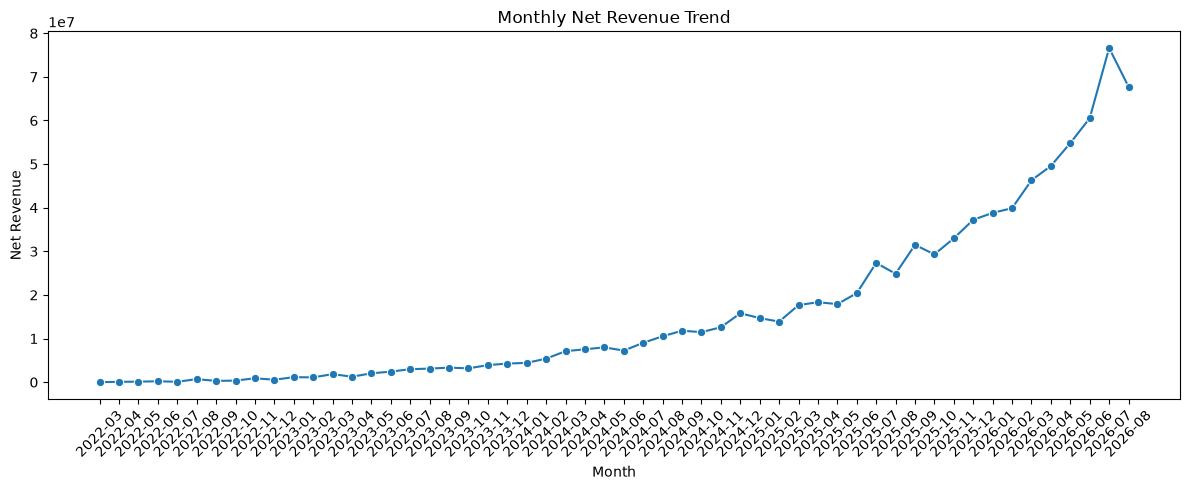

In [21]:
# Cell 21 — Monthly revenue trend

monthly_eda = (
    orders_valid.assign(month=orders_valid["order_date"].dt.to_period("M").astype(str))
    .groupby("month", as_index=False)["net_revenue"]
    .sum()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_eda, x="month", y="net_revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Net Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.tight_layout()
plt.show()


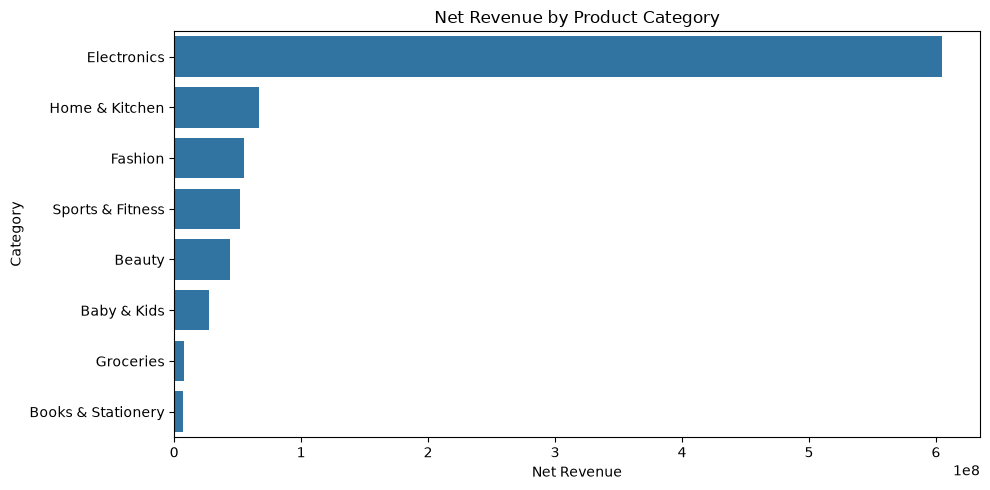

In [22]:
# Cell 22 — Category-wise revenue

orders_products = orders_valid.merge(
    products_clean[["product_id", "product_name", "category"]],
    on="product_id",
    how="left"
)

category_eda = (
    orders_products.groupby("category", as_index=False)["net_revenue"]
    .sum()
    .sort_values("net_revenue", ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(data=category_eda, x="net_revenue", y="category")
plt.title("Net Revenue by Product Category")
plt.xlabel("Net Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


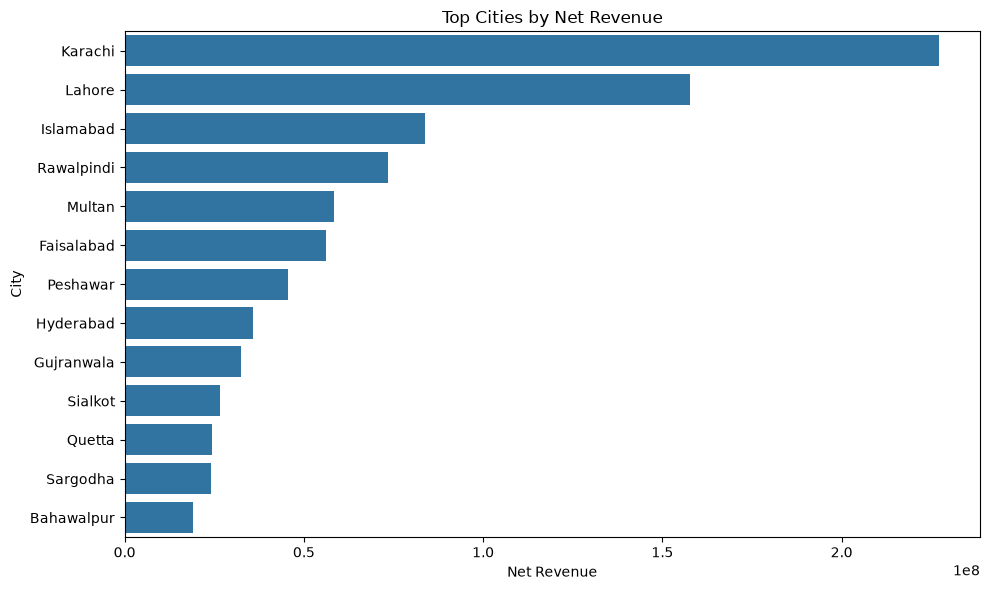

In [23]:
# Cell 23 — City-wise revenue

orders_customers = orders_valid.merge(
    customers_clean[["customer_id", "city"]],
    on="customer_id",
    how="left"
)

city_eda = (
    orders_customers.groupby("city", as_index=False)["net_revenue"]
    .sum()
    .sort_values("net_revenue", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=city_eda, x="net_revenue", y="city")
plt.title("Top Cities by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("City")
plt.tight_layout()
plt.show()


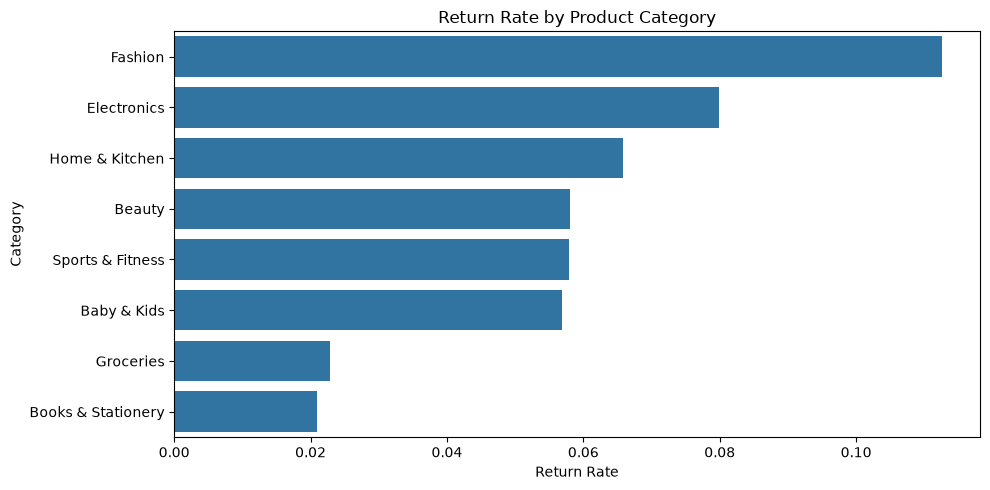

,category,orders,returned_orders,return_rate
4,Fashion,12236,1377,0.112537
3,Electronics,11536,921,0.079837
6,Home & Kitchen,7619,502,0.065888
1,Beauty,11687,678,0.058013
7,Sports & Fitness,7063,409,0.057907
0,Baby & Kids,3746,213,0.056861
5,Groceries,6081,139,0.022858
2,Books & Stationery,4922,103,0.020926


In [24]:
# Cell 24 — Return rate by category

orders_products["is_returned"] = (
    orders_products["returned"]
    .astype(str).str.strip().str.lower()
    .isin(["yes", "true", "1"])
)

return_by_category = (
    orders_products.groupby("category")
    .agg(
        orders=("order_id", "count"),
        returned_orders=("is_returned", "sum")
    )
    .reset_index()
)

return_by_category["return_rate"] = (
    return_by_category["returned_orders"] / return_by_category["orders"]
)

return_by_category = return_by_category.sort_values(
    "return_rate", ascending=False
)

plt.figure(figsize=(10, 5))
sns.barplot(data=return_by_category, x="return_rate", y="category")
plt.title("Return Rate by Product Category")
plt.xlabel("Return Rate")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

display(return_by_category)


### Your three business insights

Write at least three insights below after looking at your actual charts.

A strong insight has this structure:

**Finding → Why it matters → Business action**

Example format:

1. **Finding:** [your result]  
   **Why it matters:** [business impact]  
   **Action:** [recommended action]

2. **Finding:** ...

3. **Finding:** ...


# Task D — Customer Churn Modeling

## Preventing leakage

We will create every predictor using information available **on or before 31 May 2026**.

The churn target is then measured using purchases from **1 June 2026 through 31 August 2026**.

This prevents future purchase information from entering the predictors.

Required features:

- Total orders
- Total spending
- Average order value
- Days since last order as of 31 May 2026
- Return rate
- Average delivery days
- Age
- Membership type


In [25]:
# Cell 25 — Define the churn observation and target windows

FEATURE_END = pd.Timestamp("2026-05-31")
TARGET_START = pd.Timestamp("2026-06-01")
TARGET_END = pd.Timestamp("2026-08-31")

print("Feature period ends:", FEATURE_END.date())
print("Target period:", TARGET_START.date(), "to", TARGET_END.date())


Feature period ends: 2026-05-31
Target period: 2026-06-01 to 2026-08-31


In [26]:
# Cell 26 — Prepare valid order history for churn

orders_churn = orders_valid.copy()
orders_churn["order_date"] = pd.to_datetime(orders_churn["order_date"], errors="coerce")

pre_cutoff = orders_churn[
    orders_churn["order_date"] <= FEATURE_END
].copy()

target_period = orders_churn[
    orders_churn["order_date"].between(TARGET_START, TARGET_END, inclusive="both")
].copy()

print("Orders available for features:", len(pre_cutoff))
print("Orders available for churn target:", len(target_period))


Orders available for features: 49640
Orders available for churn target: 15250


In [27]:
# Cell 27 — Build customer-level churn features

# Customers who purchased on or before 31 May 2026 are eligible.
eligible_customers = pre_cutoff["customer_id"].dropna().unique()

# Create return flag BEFORE aggregation
pre_cutoff["is_returned"] = (
    pre_cutoff["returned"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1"])
)

feature_agg = (
    pre_cutoff.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("net_revenue", "sum"),
        average_order_value=("net_revenue", "mean"),
        last_order_date=("order_date", "max"),
        return_rate=("is_returned", "mean"),
        average_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

feature_agg["days_since_last_order"] = (
    FEATURE_END - feature_agg["last_order_date"]
).dt.days

# Customer demographics/membership
customer_features = customers_clean[
    ["customer_id", "age", "membership_type"]
].copy()

churn_df = customer_features.merge(
    feature_agg,
    on="customer_id",
    how="inner"
)

# Target: 1 if no purchase during target window; otherwise 0
target_customer_ids = set(
    target_period["customer_id"].dropna().unique()
)

churn_df["churn"] = (
    ~churn_df["customer_id"].isin(target_customer_ids)
).astype(int)

feature_columns = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "days_since_last_order",
    "return_rate",
    "average_delivery_days",
    "age",
    "membership_type"
]

display(churn_df[feature_columns + ["churn"]].head())

print("Customers in churn dataset:", len(churn_df))
print("Churn rate:", churn_df["churn"].mean())

,total_orders,total_spending,average_order_value,days_since_last_order,return_rate,average_delivery_days,age,membership_type,churn
0,3,6229.49896,2076.499653,3,0.0,4.666667,33.0,Silver,0
1,6,24102.46210,4017.077017,107,0.0,3.166667,25.0,Standard,1
2,5,14400.81290,2880.162580,13,0.0,3.000000,26.0,Standard,1
3,8,76312.80669,9539.100836,19,0.0,3.500000,27.0,Standard,0
4,3,50020.16297,16673.387657,440,0.0,3.000000,24.0,Standard,1


Customers in churn dataset: 6535
Churn rate: 0.49058913542463656


In [28]:
# Cell 28 — Check churn data quality and target balance

display(churn_df[feature_columns + ["churn"]].isna().sum().to_frame("missing"))
display(churn_df["churn"].value_counts().rename_axis("churn").to_frame("count"))
display(churn_df["churn"].value_counts(normalize=True).rename_axis("churn").to_frame("proportion"))


,missing
total_orders,0
total_spending,0
average_order_value,0
days_since_last_order,0
return_rate,0
average_delivery_days,0
age,87
membership_type,0
churn,0


,count
churn,
0,3329
1,3206


,proportion
churn,
0,0.509411
1,0.490589


## Important modeling decision

Do not randomly delete customers just because they have missing `age` or `membership_type`.

The preprocessing pipeline below will:

- impute numeric variables with the median
- impute categorical variables with the most frequent category
- scale numeric variables for Logistic Regression
- one-hot encode membership type

This keeps the modeling dataset reproducible and avoids unnecessary data loss.


In [29]:
# Cell 29 — Train/test split and preprocessing

X = churn_df[feature_columns].copy()
y = churn_df["churn"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_features = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "days_since_last_order",
    "return_rate",
    "average_delivery_days",
    "age"
]

categorical_features = ["membership_type"]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (5228, 8)
Test shape: (1307, 8)


In [30]:
# Cell 30 — Logistic Regression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

def evaluate_binary_model(name, y_true, y_pred, y_prob):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob)
    }

logistic_metrics = evaluate_binary_model(
    "Logistic Regression",
    y_test, logistic_pred, logistic_prob
)

logistic_metrics


{'model': 'Logistic Regression',
 'accuracy': 0.7153787299158378,
 'precision': 0.6614645858343338,
 'recall': 0.859594383775351,
 'f1': 0.7476255088195387,
 'roc_auc': 0.7868172384553039}

              precision    recall  f1-score   support

           0       0.81      0.58      0.67       666
           1       0.66      0.86      0.75       641

    accuracy                           0.72      1307
   macro avg       0.74      0.72      0.71      1307
weighted avg       0.74      0.72      0.71      1307



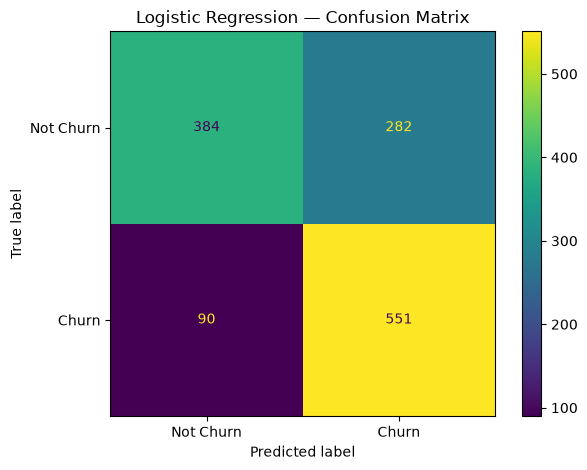

In [31]:
# Cell 31 — Logistic Regression confusion matrix

print(classification_report(y_test, logistic_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    display_labels=["Not Churn", "Churn"]
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [32]:
# Cell 32 — Random Forest

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_metrics = evaluate_binary_model(
    "Random Forest",
    y_test, rf_pred, rf_prob
)

rf_metrics


{'model': 'Random Forest',
 'accuracy': 0.6970160673297628,
 'precision': 0.666214382632293,
 'recall': 0.765990639625585,
 'f1': 0.7126269956458636,
 'roc_auc': 0.7626678941031515}

              precision    recall  f1-score   support

           0       0.74      0.63      0.68       666
           1       0.67      0.77      0.71       641

    accuracy                           0.70      1307
   macro avg       0.70      0.70      0.70      1307
weighted avg       0.70      0.70      0.70      1307



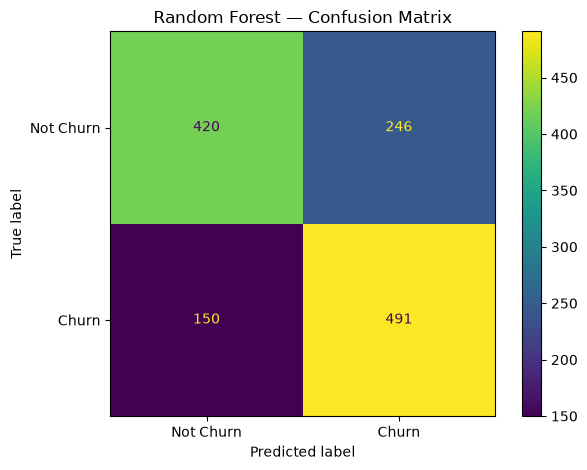

In [33]:
# Cell 33 — Random Forest confusion matrix

print(classification_report(y_test, rf_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Not Churn", "Churn"]
)
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()


In [34]:
# Cell 34 — Compare the two ML models

ml_comparison = pd.DataFrame([logistic_metrics, rf_metrics])
ml_comparison.sort_values("roc_auc", ascending=False)


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.715379,0.661465,0.859594,0.747626,0.786817
1,Random Forest,0.697016,0.666214,0.765991,0.712627,0.762668


### Your model-selection explanation

Do not automatically choose the model with the highest accuracy.

Write 2–4 sentences considering:

- Precision
- Recall
- F1
- ROC-AUC
- the business cost of missing a likely churner
- model simplicity/explainability

Then choose the model you will deploy in Streamlit.


# Task E — Feed-Forward Neural Network

The brief asks for a small network such as:

**32 → 16 → 1**

We will use the same train/test split as the classical ML models.

Because the model receives numeric data, we first transform the preprocessed features into a dense matrix.


In [35]:
# Cell 35 — Transform churn data for the neural network

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays when necessary
if hasattr(X_train_processed, "toarray"):
    X_train_nn = X_train_processed.toarray()
    X_test_nn = X_test_processed.toarray()
else:
    X_train_nn = np.asarray(X_train_processed)
    X_test_nn = np.asarray(X_test_processed)

print("Neural network input shape:", X_train_nn.shape)


Neural network input shape: (5228, 11)


In [36]:
# Cell 36 — TensorFlow neural network 32 -> 16 -> 1

import tensorflow as tf

tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_nn.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_nn,
    y_train.to_numpy(),
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

nn_prob = nn_model.predict(X_test_nn, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)

nn_metrics = evaluate_binary_model(
    "Neural Network",
    y_test, nn_pred, nn_prob
)

nn_metrics


{'model': 'Neural Network',
 'accuracy': 0.7031369548584545,
 'precision': 0.6489988221436984,
 'recall': 0.859594383775351,
 'f1': 0.7395973154362416,
 'roc_auc': 0.779693890458321}

              precision    recall  f1-score   support

           0       0.80      0.55      0.65       666
           1       0.65      0.86      0.74       641

    accuracy                           0.70      1307
   macro avg       0.73      0.71      0.70      1307
weighted avg       0.73      0.70      0.70      1307



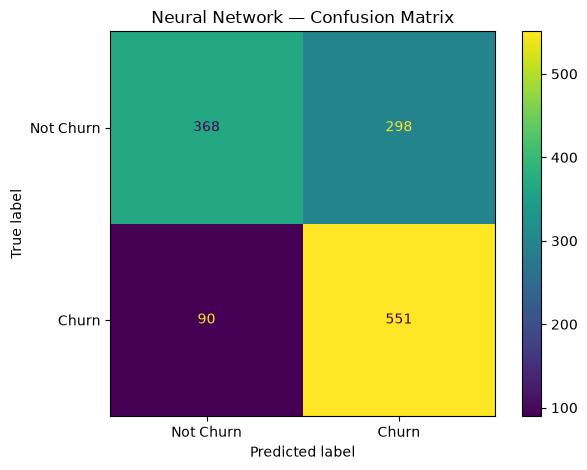

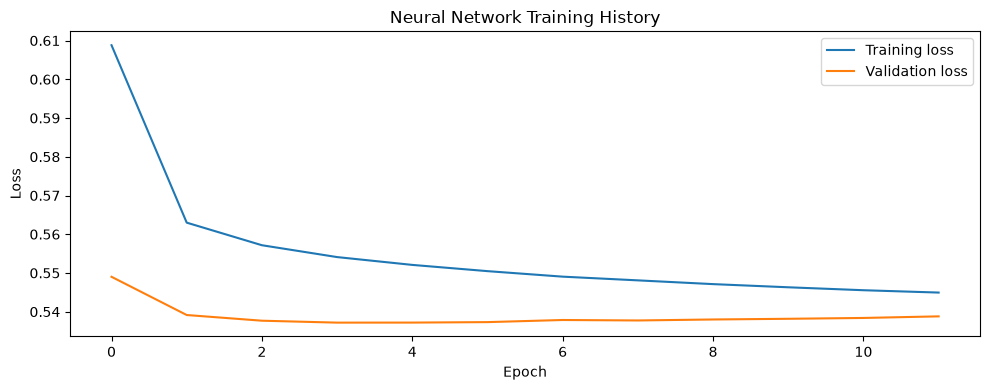

In [37]:
# Cell 37 — Neural network evaluation

print(classification_report(y_test, nn_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nn_pred,
    display_labels=["Not Churn", "Churn"]
)
plt.title("Neural Network — Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Neural Network Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [38]:
# Cell 38 — Compare all churn models

all_churn_metrics = pd.DataFrame([
    logistic_metrics,
    rf_metrics,
    nn_metrics
]).sort_values("roc_auc", ascending=False)

display(all_churn_metrics)

all_churn_metrics.to_csv(
    "outputs/churn_model_comparison.csv",
    index=False
)


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.715379,0.661465,0.859594,0.747626,0.786817
2,Neural Network,0.703137,0.648999,0.859594,0.739597,0.779694
1,Random Forest,0.697016,0.666214,0.765991,0.712627,0.762668


### Deep Learning conclusion

Write 2–3 sentences:

- Did the neural network outperform Logistic Regression or Random Forest?
- Was the extra complexity justified for this structured dataset?
- Which model would you deploy and why?


# Task F — NLP Sentiment Analysis

Required labels:

- Rating 1–2 → Negative
- Rating 3 → Neutral
- Rating 4–5 → Positive

Required model:

**TF-IDF → Logistic Regression**

We must fit TF-IDF only on the training set. This prevents text preprocessing leakage from the test set.


In [39]:
# Cell 39 — Prepare NLP dataset

X_text = reviews_nlp["review_text"].astype(str)
y_sentiment = reviews_nlp["sentiment"]

X_text_train, X_text_test, y_sent_train, y_sent_test = train_test_split(
    X_text,
    y_sentiment,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_sentiment
)

print("Training reviews:", len(X_text_train))
print("Test reviews:", len(X_text_test))
display(y_sentiment.value_counts())


Training reviews: 20695
Test reviews: 5174


sentiment
Positive    18410
Neutral      5454
Negative     2005
Name: count, dtype: int64

In [40]:
# Cell 40 — TF-IDF + Logistic Regression

from sklearn.feature_extraction.text import TfidfVectorizer

sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

sentiment_model.fit(X_text_train, y_sent_train)

sent_pred = sentiment_model.predict(X_text_test)

sentiment_metrics = {
    "accuracy": accuracy_score(y_sent_test, sent_pred),
    "precision_macro": precision_score(
        y_sent_test, sent_pred, average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        y_sent_test, sent_pred, average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        y_sent_test, sent_pred, average="macro", zero_division=0
    )
}

sentiment_metrics


{'accuracy': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'f1_macro': 1.0}

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       401
     Neutral       1.00      1.00      1.00      1091
    Positive       1.00      1.00      1.00      3682

    accuracy                           1.00      5174
   macro avg       1.00      1.00      1.00      5174
weighted avg       1.00      1.00      1.00      5174



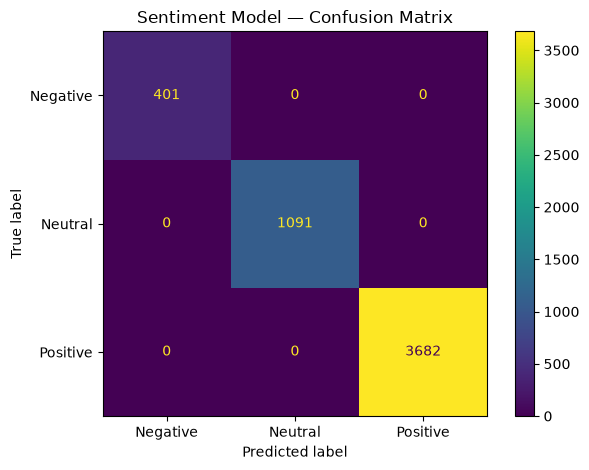

In [41]:
# Cell 41 — Sentiment evaluation

print(classification_report(
    y_sent_test,
    sent_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_sent_test,
    sent_pred,
    labels=["Negative", "Neutral", "Positive"],
    display_labels=["Negative", "Neutral", "Positive"]
)
plt.title("Sentiment Model — Confusion Matrix")
plt.tight_layout()
plt.show()


### NLP limitation

Write at least one limitation.

A strong answer should distinguish between:

- **sentiment labels created from star ratings**, and
- **true semantic sentiment expressed in the text**.

If the review text contains rating-related wording, the model may learn shortcuts. Report what you observe rather than assuming the model is perfect.


# Task G Preparation — Save models for Streamlit

The hackathon requires saved models to be loaded by the Streamlit application rather than hard-coded predictions.

Before saving, decide which churn model you will deploy based on your evaluation above.


In [42]:
# Cell 42 — Save the selected churn model and sentiment model

import joblib

# Change this if your written model-selection decision chooses Random Forest.
selected_churn_model = logistic_model

joblib.dump(
    selected_churn_model,
    "models/churn_model.joblib"
)

joblib.dump(
    sentiment_model,
    "models/sentiment_tfidf_logistic.joblib"
)

print("Saved:")
print(" - models/churn_model.joblib")
print(" - models/sentiment_tfidf_logistic.joblib")


Saved:
 - models/churn_model.joblib
 - models/sentiment_tfidf_logistic.joblib


In [43]:
# Cell 43 — Save the neural network and its preprocessing object

nn_model.save("models/churn_nn.keras")
joblib.dump(preprocessor, "models/churn_nn_preprocessor.joblib")

with open("outputs/churn_nn_input_columns.json", "w", encoding="utf-8") as f:
    json.dump(feature_columns, f, indent=2)

print("Neural network and preprocessing artifacts saved.")


Neural network and preprocessing artifacts saved.


In [44]:
# Cell 44 — Save key analysis outputs

sql_total_revenue.to_csv("outputs/sql_total_revenue.csv", index=False)
sql_top_customers.to_csv("outputs/sql_top_customers.csv", index=False)
sql_category.to_csv("outputs/sql_category_revenue.csv", index=False)
sql_monthly.to_csv("outputs/sql_monthly_revenue.csv", index=False)
sql_top_products.to_csv("outputs/sql_top_products.csv", index=False)

return_by_category.to_csv("outputs/return_rate_by_category.csv", index=False)
churn_df.to_csv("outputs/churn_dataset.csv", index=False)

with open("outputs/sentiment_metrics.json", "w", encoding="utf-8") as f:
    json.dump(sentiment_metrics, f, indent=2)

print("Analysis outputs saved.")


Analysis outputs saved.


# Final self-check before Streamlit

You should now have:

```text
ecommerce_hackathon.db
hackathon_notebook.ipynb

models/
    churn_model.joblib
    sentiment_tfidf_logistic.joblib
    churn_nn.keras
    churn_nn_preprocessor.joblib

sql/
    business_queries.sql

outputs/
    churn_dataset.csv
    churn_model_comparison.csv
    sentiment_metrics.json
    SQL result files
```

## What you still need to build yourself

### Streamlit
Create `app.py` with three sections:

1. **Dashboard**
   - total revenue
   - total orders
   - total customers
   - monthly revenue
   - category revenue
   - at least three outputs coming from SQL queries

2. **Churn Prediction**
   - input fields for the eight churn features
   - load `models/churn_model.joblib`
   - display prediction and probability

3. **Sentiment Analysis**
   - text input
   - load `models/sentiment_tfidf_logistic.joblib`
   - display predicted sentiment

### Deployment
Then:

1. Create GitHub repository.
2. Push the project.
3. Add `requirements.txt`.
4. Deploy `app.py` on Streamlit Community Cloud.
5. Test the live application.
6. Submit GitHub URL, live Streamlit URL, SQL file, notebook/Python files, saved models, requirements and README.


# Viva / Presentation Questions You Should Be Able to Answer

1. Why did you use SQLite instead of converting the whole database to CSV?
2. What data-quality problems did you find?
3. Why did you remove or retain invalid records?
4. How did you define net revenue?
5. Why is the churn feature cutoff 31 May 2026?
6. How did you prevent target leakage?
7. Why is accuracy alone insufficient for churn?
8. Why did you choose your final churn model?
9. Why did you use a 32→16→1 neural network?
10. Was deep learning worth the extra complexity?
11. How did you create sentiment labels?
12. Why did you use TF-IDF?
13. What is a limitation of rating-based sentiment labels?
14. Why must the Streamlit app load saved models?
15. Which dashboard outputs are produced directly by SQL?
